In [1]:
from standard_imports import *
from loaders import index
from ModelSimlink import RadiativeTransitions
from plots import splt
from Tools import LinesManipulator
from scipy.optimize import curve_fit

In [2]:
data = index.load_index_and_data( "TestData/RfPen/20230620" ) + index.load_index_and_data( "TestData/PlasmaBIC/20241031" )

Avantes spectrum TestData/RfPen/20230620\New Experiment0005.Raw8 normalized by a factor of 0.200000 s
Avantes spectrum TestData/RfPen/20230620\New Experiment0006.Raw8 normalized by a factor of 0.200000 s
Avantes spectrum TestData/RfPen/20230620\New Experiment0007.Raw8 normalized by a factor of 0.200000 s
Avantes spectrum TestData/RfPen/20230620\New Experiment0008.Raw8 normalized by a factor of 0.200000 s
Avantes spectrum TestData/RfPen/20230620\New Experiment0013.Raw8 normalized by a factor of 0.200000 s
Avantes spectrum TestData/RfPen/20230620\New Experiment0014.Raw8 normalized by a factor of 0.200000 s
Avantes spectrum TestData/RfPen/20230620\New Experiment0015.Raw8 normalized by a factor of 0.200000 s
Avantes spectrum TestData/RfPen/20230620\New Experiment0016.Raw8 normalized by a factor of 0.200000 s
8 rows loaded
Avantes spectrum TestData/PlasmaBIC/20241031\101_6us.RAW8 normalized by a factor of 0.400000 s
Avantes spectrum TestData/PlasmaBIC/20241031\102_6us.RAW8 normalized by a f

In [3]:
worker = LinesManipulator.LinesManipulator()

In [4]:
file = "CalibrationData/Calib_20250204_FCUVIR600.csv"

calib_spectrum = pd.read_csv(file, index_col = False).to_dict('list')
polydeg = 1

for d in data:
    d['wl_realigned'] = worker.realign_wl( d['avantes']['wl'], d['avantes']['int'] )
    d['int_withoutbaseline'] = worker.remove_baseline( d['avantes']['int'] )
    d['cal'] = worker.estimate_calibration( d['wl_realigned'], d['int_withoutbaseline'], calib_spectrum, all_lines = RadiativeTransitions.RadiativeTransitions().linesList(), polydeg=polydeg )

Realigned with y = -0.00x^2 +1.00x -0.26
Initializing class Levels
Realigned with y = -0.00x^2 +1.00x -0.22
Realigned with y = -0.00x^2 +1.00x -0.19
Realigned with y = 0.00x^2 +1.00x -0.10
Realigned with y = -0.00x^2 +1.00x -0.18
Realigned with y = 0.00x^2 +1.00x -0.15
Realigned with y = -0.00x^2 +1.00x -0.16
Realigned with y = 0.00x^2 +1.00x -0.12
Realigned with y = 0.00x^2 +1.00x +0.96
Realigned with y = 0.00x^2 +1.00x +1.33
Realigned with y = 0.00x^2 +1.00x +1.24
Realigned with y = 0.00x^2 +1.00x +0.91
Realigned with y = 0.00x^2 +1.00x +0.90
Realigned with y = 0.00x^2 +1.00x +1.24
Realigned with y = 0.00x^2 +1.00x +0.99
Realigned with y = 0.00x^2 +1.00x +0.99
Realigned with y = 0.00x^2 +1.00x +1.17
Realigned with y = 0.00x^2 +1.00x +0.94
Realigned with y = -0.00x^2 +1.00x +0.21
Realigned with y = -0.00x^2 +1.00x +0.45


In [6]:
xs = np.linspace( 650, 980 )

theocal = np.log10( np.interp( xs, calib_spectrum['wl'], calib_spectrum['f_normalized'] ) )

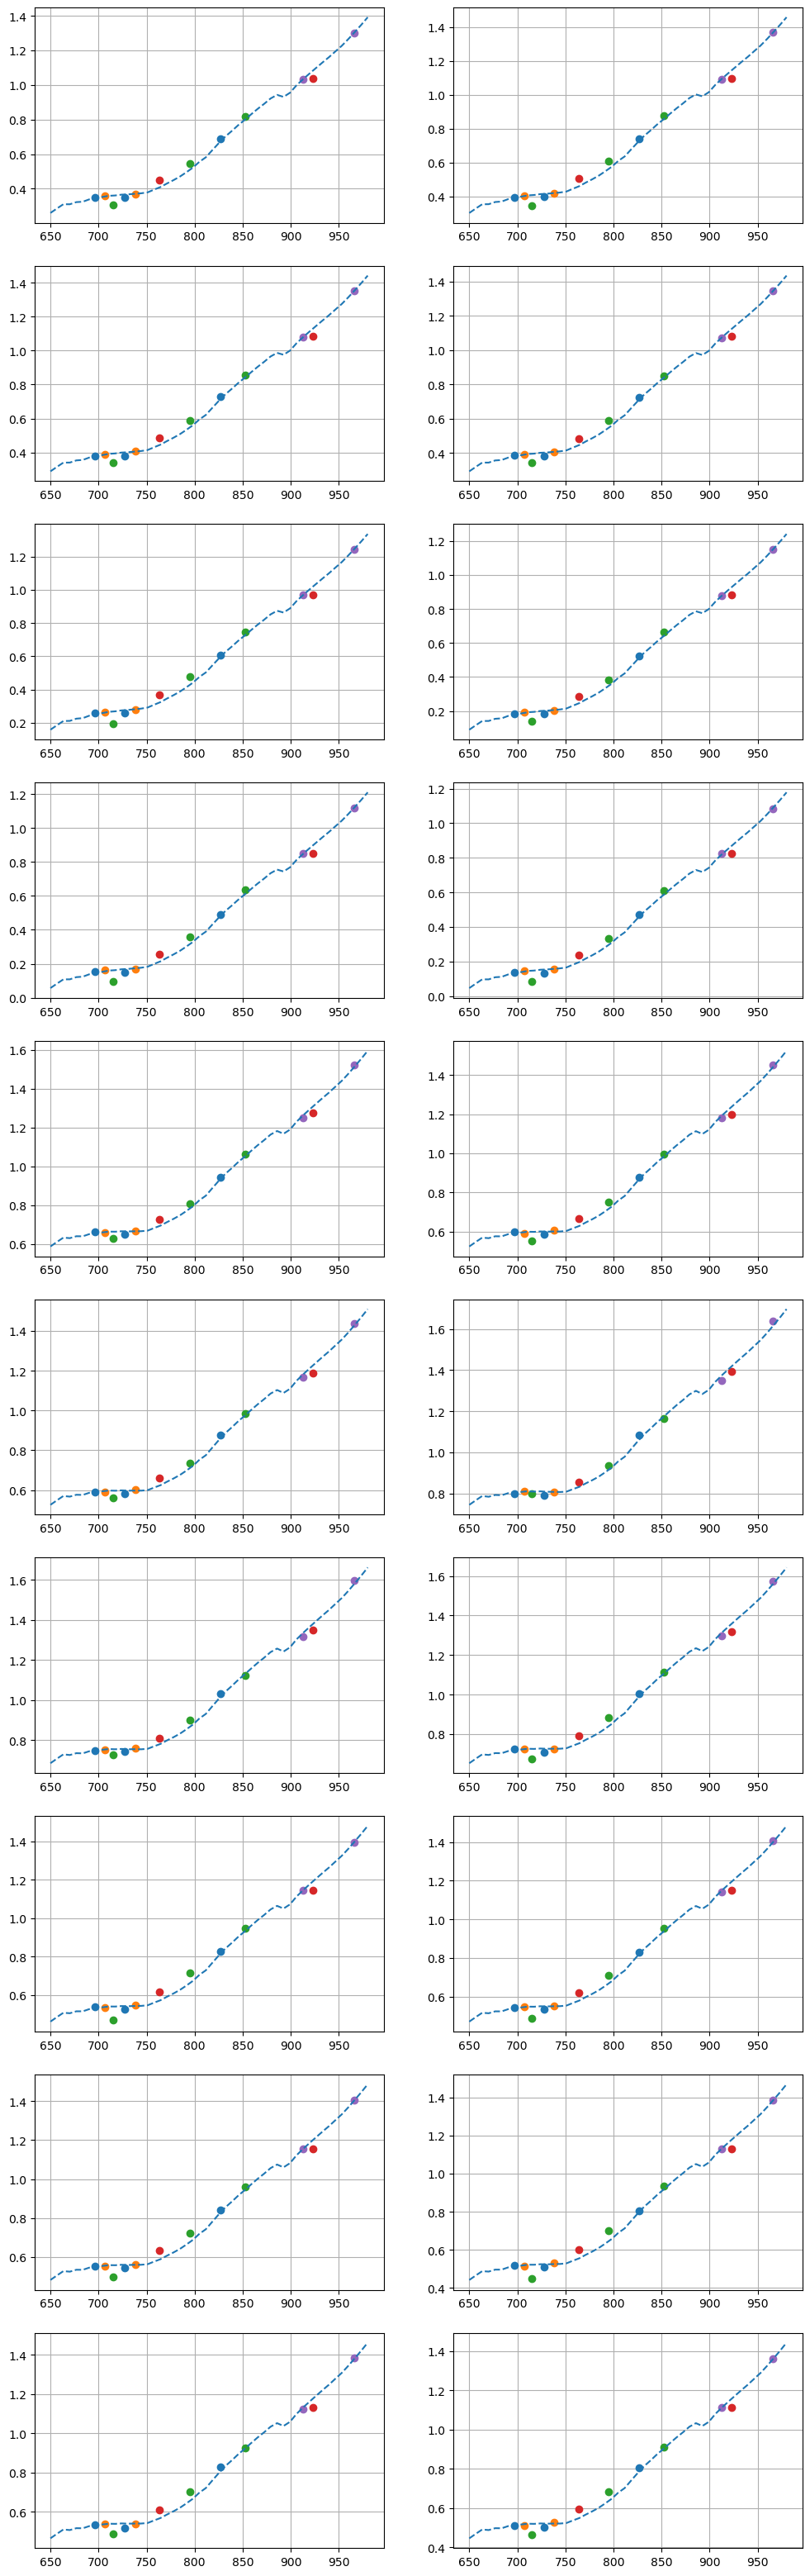

In [9]:
splt.init( len( data ) / 2 + 1, 2 )

colors = plt.list_colors()

for d in data:
    splt.next()
    for x, y, col in zip( d['cal']['xf'], d['cal']['ys'], d['cal']['label'] ):
        plt.plot( x, y, 'o', color = colors[col] )

    plt.plot( xs, theocal + np.polyval( d['cal']['p'][:polydeg+1], xs ) , '--' )
